# Elementos finitos em 1D: uma construção passo a passo

Neste notebook resolvemos um problema de Poisson unidimensional com elementos lineares (P1). Intercale as explicações com as células de código: cada resultado numérico corresponde diretamente a uma etapa da formulação matemática.

**Objetivos:** construir a formulação fraca, entender as funções de forma, montar o sistema global, impor Dirichlet e comparar a aproximação com a solução exata.

## Formulação forte e fraca

O problema é

$$-u''(x)=2, \quad x\in(0,1), \qquad u(0)=u(1)=0.$$

A solução analítica é $u(x)=x(1-x)$. Multiplicando a equação por uma função teste $v$ que se anula na fronteira e integrando por partes, obtemos a formulação fraca:

$$\int_0^1 u'(x)v'(x)\,dx=\int_0^1 2v(x)\,dx. $$

No método de elementos finitos, procuramos $u_h$ no espaço de funções contínuas e lineares em cada elemento da malha.

## Elemento de referência e funções P1

No elemento de referência $\widehat K=[0,1]$, usamos $\widehat N_1(\xi)=1-\xi$ e $\widehat N_2(\xi)=\xi$. Em um elemento físico $K=[x_a,x_b]$, com comprimento $h_K$, suas derivadas são $N_1'=-1/h_K$ e $N_2'=1/h_K$. Portanto,

$$A^K=\frac{1}{h_K}\begin{bmatrix}1&-1\\-1&1\end{bmatrix}, \qquad b^K=\begin{bmatrix}h_K\\h_K\end{bmatrix}. $$

A célula seguinte cria uma malha de quatro elementos, calcula essas contribuições e realiza a montagem global.

1) MALHA
Nós:
[0.   0.25 0.5  0.75 1.  ]

Conectividade dos elementos:
[[0 1]
 [1 2]
 [2 3]
 [3 4]]

2) MATRIZES LOCAIS

Elemento K0 = [0.00, 0.25]
A_local =
[[ 4. -4.]
 [-4.  4.]]
b_local =
[0.25 0.25]

Elemento K1 = [0.25, 0.50]
A_local =
[[ 4. -4.]
 [-4.  4.]]
b_local =
[0.25 0.25]

Elemento K2 = [0.50, 0.75]
A_local =
[[ 4. -4.]
 [-4.  4.]]
b_local =
[0.25 0.25]

Elemento K3 = [0.75, 1.00]
A_local =
[[ 4. -4.]
 [-4.  4.]]
b_local =
[0.25 0.25]

3) SISTEMA GLOBAL ANTES DAS CONDIÇÕES DE DIRICHLET

Matriz global A:
[[ 4. -4.  0.  0.  0.]
 [-4.  8. -4.  0.  0.]
 [ 0. -4.  8. -4.  0.]
 [ 0.  0. -4.  8. -4.]
 [ 0.  0.  0. -4.  4.]]

Vetor global b:
[0.25 0.5  0.5  0.5  0.25]

4) SISTEMA REDUZIDO APÓS DIRICHLET

A_interior:
[[ 8. -4.  0.]
 [-4.  8. -4.]
 [ 0. -4.  8.]]

b_interior:
[0.5 0.5 0.5]

5) COEFICIENTES NODAIS ENCONTRADOS

U_interior =
[0.1875 0.25   0.1875]

Vetor completo U =
[0.     0.1875 0.25   0.1875 0.    ]

Valores nó a nó:
U0 = u_h(0.00) = 0.00000000
U1 = u_h(0.25) = 0.1

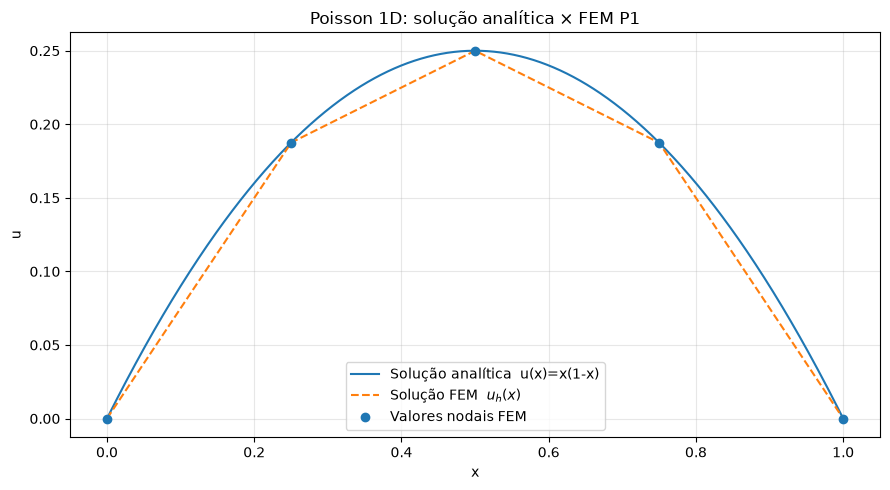

In [2]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# PROBLEMA
# ============================================================
# Resolver com FEM P1:
#
#     -u''(x) = 2,   x em (0,1)
#      u(0) = 0
#      u(1) = 0
#
# Solução analítica:
#
#     u(x) = x(1-x)
#
# Usaremos uma malha uniforme com h = 1/4:
#
#     x0=0 --- x1=1/4 --- x2=1/2 --- x3=3/4 --- x4=1
#
# Portanto:
#   5 nós globais
#   4 elementos
#   5 DOFs globais
#   3 DOFs livres (U1, U2, U3), pois U0=U4=0
# ============================================================


# ============================================================
# 1. MALHA
# ============================================================

h = 1/4

nos = np.array([0.0, 0.25, 0.50, 0.75, 1.0])

# Cada linha indica os dois nós globais de um elemento:
#
# K0 -> nós globais 0 e 1
# K1 -> nós globais 1 e 2
# K2 -> nós globais 2 e 3
# K3 -> nós globais 3 e 4
elementos = np.array([
    [0, 1],
    [1, 2],
    [2, 3],
    [3, 4]
], dtype=int)

num_nos = len(nos)

print("=" * 70)
print("1) MALHA")
print("=" * 70)
print("Nós:")
print(nos)
print("\nConectividade dos elementos:")
print(elementos)


# ============================================================
# 2. ELEMENTO DE REFERÊNCIA E MATRIZ LOCAL
# ============================================================
#
# No elemento de referência:
#
#     K_hat = [0,1]
#
# funções de forma:
#
#     N_hat_1(xi) = 1 - xi
#     N_hat_2(xi) = xi
#
# O mapeamento para um elemento físico K=[xa,xb] é:
#
#     x = xa + h_K * xi
#
# com
#
#     h_K = xb - xa
#
# Da regra da cadeia:
#
#     dN1/dx = -1/h_K
#     dN2/dx =  1/h_K
#
# Para Poisson:
#
#     A^K_mn = integral_K N'_m N'_n dx
#
# resultando em:
#
#     A^K = (1/h_K) [[ 1, -1],
#                    [-1,  1]]
#
# Como f=2:
#
#     b^K_m = integral_K 2*N_m dx
#
# Cada função de forma local tem área h_K/2.
# Logo:
#
#     b^K = [h_K, h_K]^T
# ============================================================

def matrizes_locais(xa, xb):
    hK = xb - xa

    A_local = (1.0 / hK) * np.array([
        [ 1.0, -1.0],
        [-1.0,  1.0]
    ])

    b_local = hK * np.array([1.0, 1.0])

    return A_local, b_local


print("\n" + "=" * 70)
print("2) MATRIZES LOCAIS")
print("=" * 70)

for e, conectividade in enumerate(elementos):
    i, j = conectividade
    xa, xb = nos[i], nos[j]

    A_local, b_local = matrizes_locais(xa, xb)

    print(f"\nElemento K{e} = [{xa:.2f}, {xb:.2f}]")
    print("A_local =")
    print(A_local)
    print("b_local =")
    print(b_local)


# ============================================================
# 3. MONTAGEM DA MATRIZ GLOBAL A E DO VETOR GLOBAL b
# ============================================================
#
# Inicialmente:
#
#     A = matriz 5x5 de zeros
#     b = vetor de 5 zeros
#
# Para cada elemento, somamos suas contribuições nas posições
# correspondentes aos seus nós globais.
#
# Exemplo para K1, que possui nós globais [1,2]:
#
#     A_local[0,0] -> A[1,1]
#     A_local[0,1] -> A[1,2]
#     A_local[1,0] -> A[2,1]
#     A_local[1,1] -> A[2,2]
#
# Se uma posição já recebeu contribuição de outro elemento,
# SOMAMOS as contribuições.
# ============================================================

A = np.zeros((num_nos, num_nos))
b = np.zeros(num_nos)

for e, conectividade in enumerate(elementos):
    i, j = conectividade

    xa = nos[i]
    xb = nos[j]

    A_local, b_local = matrizes_locais(xa, xb)

    # Nós globais associados aos índices locais 0 e 1
    globais = [i, j]

    # Montagem da matriz global
    for m_local, I_global in enumerate(globais):
        for n_local, J_global in enumerate(globais):
            A[I_global, J_global] += A_local[m_local, n_local]

    # Montagem do vetor global
    for m_local, I_global in enumerate(globais):
        b[I_global] += b_local[m_local]


print("\n" + "=" * 70)
print("3) SISTEMA GLOBAL ANTES DAS CONDIÇÕES DE DIRICHLET")
print("=" * 70)

print("\nMatriz global A:")
print(A)

print("\nVetor global b:")
print(b)


# ============================================================
# 4. CONDIÇÕES DE DIRICHLET
# ============================================================
#
# Temos:
#
#     U0 = 0
#     U4 = 0
#
# Portanto, os únicos valores desconhecidos são:
#
#     U1, U2, U3
#
# Como os valores prescritos da fronteira são zero, podemos
# simplesmente pegar o bloco interior da matriz:
#
#     A_int * U_int = b_int
#
# ============================================================

nos_internos = np.array([1, 2, 3])

A_interior = A[np.ix_(nos_internos, nos_internos)]
b_interior = b[nos_internos]

print("\n" + "=" * 70)
print("4) SISTEMA REDUZIDO APÓS DIRICHLET")
print("=" * 70)

print("\nA_interior:")
print(A_interior)

print("\nb_interior:")
print(b_interior)


# ============================================================
# 5. RESOLUÇÃO DO SISTEMA LINEAR
# ============================================================

U_interior = np.linalg.solve(A_interior, b_interior)

# Agora reconstruímos o vetor completo:
#
# U = [U0, U1, U2, U3, U4]
#
# com U0=U4=0.
U = np.zeros(num_nos)
U[nos_internos] = U_interior

print("\n" + "=" * 70)
print("5) COEFICIENTES NODAIS ENCONTRADOS")
print("=" * 70)

print("\nU_interior =")
print(U_interior)

print("\nVetor completo U =")
print(U)

print("\nValores nó a nó:")
for i, (x_i, U_i) in enumerate(zip(nos, U)):
    print(f"U{i} = u_h({x_i:.2f}) = {U_i:.8f}")


# ============================================================
# 6. RECONSTRUÇÃO DA SOLUÇÃO FEM u_h(x)
# ============================================================
#
# Em cada elemento K=[xa,xb]:
#
#     u_h(x) = U_a*N1(x) + U_b*N2(x)
#
# com
#
#     N1(x) = (xb-x)/hK
#     N2(x) = (x-xa)/hK
#
# ============================================================

def u_fem(x):
    """
    Avalia a solução FEM u_h em um ponto ou array de pontos x.
    """
    x = np.asarray(x, dtype=float)
    resultado = np.zeros_like(x)

    for e, (i, j) in enumerate(elementos):
        xa, xb = nos[i], nos[j]
        hK = xb - xa

        # Inclui o extremo direito apenas no último elemento
        if e < len(elementos) - 1:
            mascara = (x >= xa) & (x < xb)
        else:
            mascara = (x >= xa) & (x <= xb)

        xK = x[mascara]

        N1 = (xb - xK) / hK
        N2 = (xK - xa) / hK

        resultado[mascara] = U[i] * N1 + U[j] * N2

    return resultado


# ============================================================
# 7. SOLUÇÃO ANALÍTICA
# ============================================================
#
# -u'' = 2
#  u'' = -2
#
# Integrando:
#
#  u' = -2x + C1
#  u  = -x^2 + C1*x + C2
#
# u(0)=0 -> C2=0
# u(1)=0 -> -1+C1=0 -> C1=1
#
# Logo:
#
#     u(x) = x - x^2 = x(1-x)
# ============================================================

def u_exata(x):
    return x * (1.0 - x)


# ============================================================
# 8. COMPARAÇÃO NUMÉRICA
# ============================================================

x_plot = np.linspace(0.0, 1.0, 1000)

u_h_plot = u_fem(x_plot)
u_exata_plot = u_exata(x_plot)

erro = u_exata_plot - u_h_plot

erro_max = np.max(np.abs(erro))
erro_L2_aprox = np.sqrt(np.trapezoid(erro**2, x_plot))

print("\n" + "=" * 70)
print("6) COMPARAÇÃO COM A SOLUÇÃO ANALÍTICA")
print("=" * 70)

print(f"\nErro máximo aproximado = {erro_max:.10f}")
print(f"Erro L2 aproximado     = {erro_L2_aprox:.10f}")

print("\nComparação nos nós:")
print(" nó       x          u_h(x)       u_exata(x)")
for i, x_i in enumerate(nos):
    print(
        f" {i:1d}    {x_i:8.4f}    "
        f"{U[i]:12.8f}    {u_exata(x_i):12.8f}"
    )


# ============================================================
# 9. GRÁFICO
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    x_plot,
    u_exata_plot,
    label="Solução analítica  u(x)=x(1-x)"
)

plt.plot(
    x_plot,
    u_h_plot,
    "--",
    label="Solução FEM  $u_h(x)$"
)

plt.scatter(
    nos,
    U,
    zorder=3,
    label="Valores nodais FEM"
)

plt.xlabel("x")
plt.ylabel("u")
plt.title("Poisson 1D: solução analítica × FEM P1")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## Visualizando a base global

Cada grau de liberdade interno está associado a uma função de base em forma de tenda. Ela vale um no seu nó, zero nos demais e tem suporte somente nos dois elementos vizinhos. A solução discreta é $u_h(x)=\sum_i U_i\varphi_i(x)$.

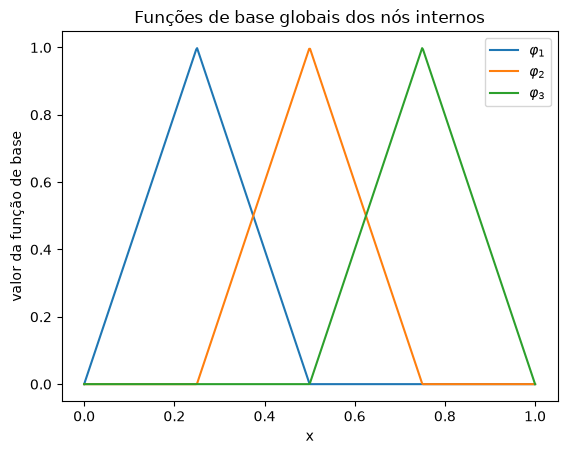

In [3]:
x_base = np.linspace(0.0, 1.0, 500)
for indice in nos_internos:
    phi = np.zeros_like(x_base)
    esquerda, centro, direita = nos[indice - 1], nos[indice], nos[indice + 1]
    mascara_esq = (x_base >= esquerda) & (x_base <= centro)
    mascara_dir = (x_base >= centro) & (x_base <= direita)
    phi[mascara_esq] = (x_base[mascara_esq] - esquerda) / (centro - esquerda)
    phi[mascara_dir] = (direita - x_base[mascara_dir]) / (direita - centro)
    plt.plot(x_base, phi, label=fr"$\varphi_{indice}$")
plt.xlabel("x")
plt.ylabel("valor da função de base")
plt.title("Funções de base globais dos nós internos")
plt.legend()
plt.show()

## Refinamento de malha e convergência

Para elementos P1, esperamos que o erro em norma $L^2$ diminua aproximadamente como $h^2$. A célula seguinte repete a montagem e a resolução em malhas mais finas.

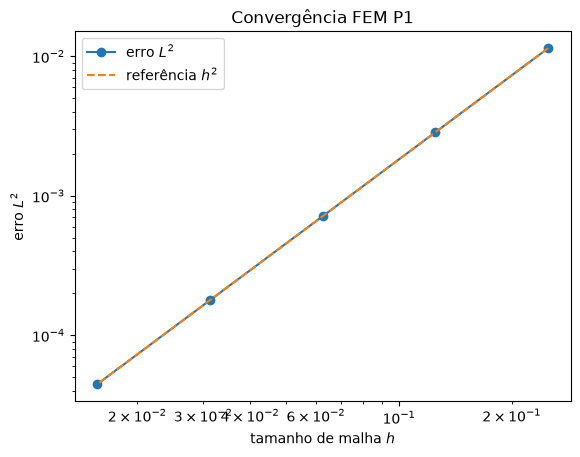

elementos =  4, erro L2 = 1.14108866e-02
elementos =  8, erro L2 = 2.85272165e-03
elementos = 16, erro L2 = 7.13180413e-04
elementos = 32, erro L2 = 1.78295103e-04
elementos = 64, erro L2 = 4.45737757e-05


In [4]:
def resolver_poisson(numero_elementos):
    x_nos = np.linspace(0.0, 1.0, numero_elementos + 1)
    A = np.zeros((numero_elementos + 1, numero_elementos + 1))
    b = np.zeros(numero_elementos + 1)
    for i in range(numero_elementos):
        A_local, b_local = matrizes_locais(x_nos[i], x_nos[i + 1])
        A[np.ix_([i, i + 1], [i, i + 1])] += A_local
        b[[i, i + 1]] += b_local
    valores = np.zeros(numero_elementos + 1)
    valores[1:-1] = np.linalg.solve(A[1:-1, 1:-1], b[1:-1])
    return x_nos, valores

elementos_por_malha = np.array([4, 8, 16, 32, 64])
erros_l2 = []
for numero_elementos in elementos_por_malha:
    x_nos, valores = resolver_poisson(numero_elementos)
    x_avaliacao = np.linspace(0.0, 1.0, 4001)
    erro = u_exata(x_avaliacao) - np.interp(x_avaliacao, x_nos, valores)
    erros_l2.append(np.sqrt(np.trapezoid(erro**2, x_avaliacao)))

h = 1.0 / elementos_por_malha
plt.loglog(h, erros_l2, "o-", label=r"erro $L^2$")
plt.loglog(h, erros_l2[0] * (h / h[0])**2, "--", label=r"referência $h^2$")
plt.xlabel(r"tamanho de malha $h$")
plt.ylabel(r"erro $L^2$")
plt.title("Convergência FEM P1")
plt.legend()
plt.show()

for numero_elementos, erro_l2 in zip(elementos_por_malha, erros_l2):
    print(f"elementos = {numero_elementos:2d}, erro L2 = {erro_l2:.8e}")

## Exercícios para explorar

1. Altere a malha para 8 ou 16 elementos e observe a redução dos erros.
2. Troque a carga constante por uma função $f(x)$ e substitua o vetor local pela integração numérica apropriada.
3. Experimente condições de Dirichlet não homogêneas; nesse caso, as contribuições conhecidas devem ser transferidas para o vetor de carga.